# [실습] 회귀 — 숫자를 예측하고 오차로 말하기

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

# Chapter 2 실습. 이 집은 얼마에 팔릴까?

**필수 머신러닝 · Chapter 2**

| Part | 주제 |
| --- | --- |
| Part 1 | 데이터와 친해지기 |
| Part 2 | 베이스라인 고르기 |
| Part 3 | 현행 방법 만들기: 사람의 시세 규칙 |
| Part 4 | 모델 만들기와 실험 기록 |
| Part 5 | 오차 들여다보기와 보고 |

## 분석 의뢰서

> **의뢰 부서**: 부동산 플랫폼 기획팀
> **목적**: 매물을 등록할 때 "이 집은 대략 얼마" 하는 적정 시세를 자동으로 제시하고 싶다.
> **제약**: 시세가 실제 거래가와 너무 다르면 판매자와 구매자 모두 플랫폼을 믿지 않게 된다.
> **질문**: 집의 정보로 거래가를 얼마나 정확히 예측할 수 있을까?

## 이 실습의 질문

> **기획팀에 "이 모델의 시세는 평균적으로 ±얼마"라고 말한다면, 어떤 지표로 얼마라고 말할 것인가? 그리고 그 숫자를 믿어도 되는 집과 믿으면 안 되는 집은 어떻게 다른가?**

Chapter 1과 같은 순서로 진행합니다. 여러분이 먼저 중개사처럼 **사람의 시세 규칙**을 만들고, 그 시세 규칙과 모델을 **같은 평가용 데이터**에서 비교합니다. 마지막에는 기획팀에 보낼 보고 메모를 씁니다.

## 이 노트북을 쓰는 법

| 표시 | 뜻 |
| --- | --- |
| **[직접 작성]** | 빈 코드 셀을 직접 채웁니다. 강의 교안의 코드를 보지 않고 먼저 써 보세요 |
| **[판단]** | 코드가 아니라 생각을 적는 칸입니다. 셀을 더블클릭해 `나의 답:` 뒤에 적으세요 |
| **[제공]** | 미리 채워 둔 코드입니다. 읽고 실행하세요 |
| **힌트** | 막혔을 때만 펼치세요 |

## 준비

Kaggle의 House Prices 대회 데이터인 `train.csv`(Ames Housing, 1,460채)를 이 노트북과 같은 폴더에 두세요.

In [18]:
# [제공] 이 실습에서 쓰는 라이브러리
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# 그래프의 한글 글꼴 (환경에 맞는 글꼴이 없으면 글자가 깨질 수 있습니다)
if platform.system() == "Windows":
    plt.rcParams["font.family"] = "Malgun Gothic"
elif platform.system() == "Darwin":
    plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

---
# Part 1. 데이터와 친해지기

강의에서는 피처 다섯 개만 썼습니다. 여기서는 데이터에 실제로 어떤 문제가 들어 있는지 직접 확인하고, 그 문제를 어떻게 다룰지 스스로 정합니다.

## 1-1. 데이터 불러오기

**[직접 작성]** `train.csv`를 불러와 `df`에 저장하고, 행과 열의 수와 처음 5행을 확인하세요.

<details><summary>힌트</summary>

`pd.read_csv("파일 이름")`, `df.shape`, `df.head()`를 쓰세요. 열이 많아서 `df.head()`는 일부만 보입니다.
</details>

In [19]:
# 1-1. 데이터 불러오기
df = pd.read_csv("train.csv")   # CSV 파일을 표(DataFrame)로 읽어 df에 저장
print("행, 열:", df.shape)       # (집 수, 정보 개수)
df.head()                        # 맨 위 5줄 미리 보기

행, 열: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 1-2. 거래가 살펴보기

**[직접 작성]** 거래가(`SalePrice`)의 평균, 중앙값, 최솟값, 최댓값을 확인하세요.

<details><summary>힌트</summary>

`df["SalePrice"].describe()`가 한 번에 보여 줍니다. 중앙값은 `50%` 줄입니다.
</details>

In [20]:
# 1-2. 거래가 요약 통계
# describe()는 개수·평균(mean)·표준편차·최솟값(min)·사분위수·최댓값(max)을 한 번에 보여 줍니다.
# 중앙값은 "50%" 줄입니다.
df["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

**[제공]** 거래가의 분포를 그려 봅니다.

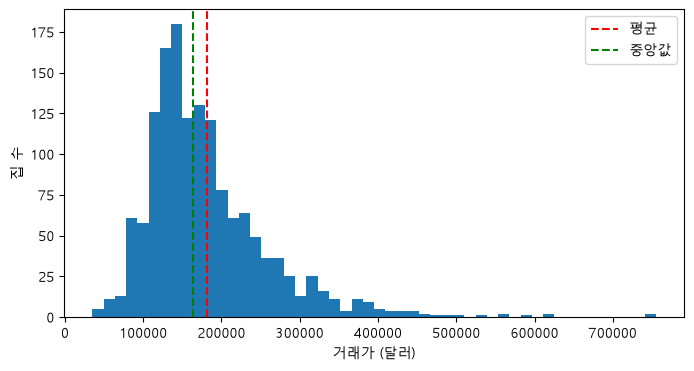

In [21]:
# [제공] 거래가 분포
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["SalePrice"], bins=50)
ax.axvline(df["SalePrice"].mean(), color="red", linestyle="--", label="평균")
ax.axvline(df["SalePrice"].median(), color="green", linestyle="--", label="중앙값")
ax.set_xlabel("거래가 (달러)")
ax.set_ylabel("집 수")
ax.legend()
plt.show()

> **[판단]** 평균과 중앙값 중 어느 쪽이 더 큰가요? 그 이유는 무엇이고, 이 특징이 "모델이 크게 틀리는 집"에 어떤 영향을 줄 것 같나요?
>
> 나의 답: 평균(약 180,921달러)이 중앙값(163,000달러)보다 큽니다. 대부분의 집은 10만~20만 달러대에 몰려 있는데, 50만~75만 달러짜리 아주 비싼 집이 소수 있어서 평균을 오른쪽(비싼 쪽)으로 끌어당기기 때문입니다(오른쪽 꼬리가 긴 분포).
> 비싼 집은 수가 적어서 모델이 배울 사례가 부족합니다. 그래서 "모델이 크게 틀리는 집"은 주로 이 비싼 집들일 것이고, 실제보다 싸게 예측할 가능성이 큽니다.

## 1-3. 빈 값 찾기

**[직접 작성]** 빈 값이 있는 열을 빈 값이 많은 순서로 10개 확인하세요.

<details><summary>힌트</summary>

`df.isna().sum()`은 열마다 빈 값의 수를 셉니다. `.sort_values(ascending=False)`로 정렬하고 `.head(10)`으로 위쪽만 보세요.
</details>

In [22]:
# 1-3. 빈 값이 많은 열 10개
# isna()는 빈 칸이면 True, sum()은 True의 개수를 셉니다 → 열마다 빈 칸 수
df.isna().sum().sort_values(ascending=False).head(10)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
dtype: int64

> **[판단]** 수영장 품질(`PoolQC`)이 1,453채나 비어 있습니다. 정말로 정보가 없는 걸까요, 아니면 다른 뜻일까요? 데이터 설명서에서는 이런 열의 빈 값(NA)을 "해당 시설 없음"으로 정의합니다. 이 점을 알면 빈 값을 어떻게 다루겠습니까?
>
> 나의 답: 정보가 없는 게 아니라 "수영장이 없음"이라는 뜻입니다. 1,460채 중 수영장이 있는 집은 7채뿐이라 1,453채가 비어 있는 것이 자연스럽습니다.
> 그래서 이런 열의 빈 값은 지우거나 평균으로 채우지 않고, "None(시설 없음)"이라는 하나의 값(범주)으로 채우겠습니다. 숫자형 시설 열(예: 차고 면적)이라면 0으로 채우는 것이 맞습니다.

## 1-4. 이 실습에서 쓰는 피처 정하기

79개를 전부 쓰면 첫 실습으로는 너무 많아서, 이 실습에서 쓸 피처 몇 개를 미리 골라 두었습니다. **[제공]** 셀을 실행해 목록을 확인하세요.

In [23]:
# [제공] 이 실습에서 쓰는 피처 목록
num_features = ["GrLivArea", "OverallQual", "YearBuilt", "YearRemodAdd", "TotalBsmtSF", "GarageCars",
                "GarageArea", "LotArea", "FullBath", "TotRmsAbvGrd", "Fireplaces", "1stFlrSF"]
cat_features = ["Neighborhood", "ExterQual", "KitchenQual", "BsmtQual", "CentralAir", "MSSubClass"]

print("숫자형:", num_features)
print("범주형:", cat_features)
print()
print("선택한 피처 중 빈 값이 있는 열:")
print(df[num_features + cat_features].isna().sum()[lambda s: s > 0])
print()
print("MSSubClass의 값:", sorted(df["MSSubClass"].unique().tolist()))

숫자형: ['GrLivArea', 'OverallQual', 'YearBuilt', 'YearRemodAdd', 'TotalBsmtSF', 'GarageCars', 'GarageArea', 'LotArea', 'FullBath', 'TotRmsAbvGrd', 'Fireplaces', '1stFlrSF']
범주형: ['Neighborhood', 'ExterQual', 'KitchenQual', 'BsmtQual', 'CentralAir', 'MSSubClass']

선택한 피처 중 빈 값이 있는 열:
BsmtQual    37
dtype: int64

MSSubClass의 값: [20, 30, 40, 45, 50, 60, 70, 75, 80, 85, 90, 120, 160, 180, 190]


> **[판단]** `MSSubClass`(주택 유형)는 20, 30, 60, 120… 처럼 숫자로 저장되어 있습니다. 이 숫자들은 "크기"를 뜻할까요? 이 열을 숫자 그대로 회귀에 넣으면 어떤 문제가 생길까요?
>
> 나의 답: 크기를 뜻하지 않습니다. 20(1946년 이후 1층집), 60(1946년 이후 2층집), 120(타운하우스)처럼 주택 유형을 구분하는 코드 번호일 뿐입니다.
> 숫자 그대로 넣으면 회귀 모델은 "120은 60의 두 배"라고 받아들여 숫자가 클수록 가격이 일정하게 오르거나 내린다는 엉터리 관계를 배웁니다. 그래서 글자(범주)로 바꾸고 원핫 인코딩해서 유형마다 따로 효과를 배우게 해야 합니다.

**[직접 작성]** 아래 두 가지를 처리하세요.

1. `MSSubClass`를 글자(범주)로 바꾼다
2. 범주형 피처(`cat_features`)의 빈 값을 `"None"`이라는 값으로 채운다

그다음 선택한 피처에 빈 값이 남지 않았는지 확인합니다.

<details><summary>힌트</summary>

`df["MSSubClass"] = df["MSSubClass"].astype(str)`, `df[cat_features] = df[cat_features].fillna("None")`. 확인은 `df[num_features + cat_features].isna().sum().sum()`이 0인지 보면 됩니다.
</details>

In [24]:
# 1-4. 전처리 두 가지
# ① MSSubClass는 "주택 유형 코드"라서 크기가 아니라 이름표입니다 → 글자로 바꿉니다
df["MSSubClass"] = df["MSSubClass"].astype(str)

# ② 범주형의 빈 칸은 설명서상 "해당 시설 없음"이므로 "None"이라는 값으로 채웁니다
df[cat_features] = df[cat_features].fillna("None")

# 확인: 선택한 피처의 빈 칸 수 합계가 0이면 성공
print("남은 빈 값 수:", df[num_features + cat_features].isna().sum().sum())

남은 빈 값 수: 0


> **[판단]** 범주형의 빈 값을 "None"이라는 값으로 채운 것은 1-3에서 본 "해당 시설 없음"이라는 설명서의 정의에 근거한 결정입니다. 이 결정이 틀릴 수 있는 경우를 하나 생각해 보세요. (예: 정말로 기록이 누락된 경우)
>
> 나의 답: 지하실이 실제로 있는데 조사원이 품질 칸을 깜빡 빠뜨린 경우입니다. 그 집은 "지하실 없음"으로 잘못 분류되어 가격이 낮게 예측될 수 있습니다.
> 이 데이터에서는 BsmtQual이 빈 37채가 모두 지하실 면적(TotalBsmtSF)이 0이라서 "없음"이라는 해석이 맞았습니다. 이렇게 다른 열과 맞춰 보면 진짜 "없음"인지 누락인지 확인할 수 있습니다.

## 1-5. 평가용 데이터 먼저 떼어 두기

Chapter 1과 같은 원칙입니다. 이후의 탐색과 시세 규칙은 **학습용 데이터만** 보고 하고, 평가용 데이터는 마지막 채점에만 씁니다.

**[직접 작성]** `df`를 학습용 80%, 평가용 20%로 나눠 `train_df`, `test_df`에 저장하세요. `random_state=42`로 합니다. (회귀 문제이므로 `stratify`는 쓰지 않습니다.)

<details><summary>힌트</summary>

`train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)`
</details>

In [25]:
# 1-5. 학습용 80% / 평가용 20%로 나누기
# random_state=42는 "섞는 방법"을 고정해서 누가 실행해도 같은 결과가 나오게 합니다.
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print("학습용:", len(train_df), "채 / 평가용:", len(test_df), "채")

학습용: 1168 채 / 평가용: 292 채


### 체크포인트

여기까지 막혀서 다음으로 넘어가지 못했다면 **아래 셀만 실행**하세요. 1-4의 처리와 1-5의 분할을 한 번에 합니다. 끝낸 사람은 실행하지 않아도 됩니다.

In [26]:
# [제공] 체크포인트: 1-5까지 끝낸 사람은 실행하지 않아도 됩니다
df = pd.read_csv("train.csv")
df["MSSubClass"] = df["MSSubClass"].astype(str)
df[cat_features] = df[cat_features].fillna("None")
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)
print(len(train_df), len(test_df))

1168 292


### 실습 도구 (실행만 하세요)

| 도구 | 하는 일 |
| --- | --- |
| `evaluate(이름, 예측)` | 평가용 데이터에서 MAE·RMSE·R²·MAPE를 보여 주고 지표를 돌려준다 |
| `make_data(피처 목록)` | 피처 목록으로 학습용·평가용 `X`, `y`를 만든다 (범주형은 원핫 인코딩) |
| `log_result(...)` | 실험 결과를 기록표에 한 줄 추가한다 |
| `run(이름, 피처, 모델)` | 모델을 학습하고 학습용·평가용 점수를 모두 채점해 기록한다 |
| `error_by_price(예측)` | 가격대별 집 수·MAE·평균 편향을 보여 준다 |

In [27]:
# [제공] 실습 도구
y_test = test_df["SalePrice"]
preds = {}          # 실험 이름 → 평가용 데이터의 예측값
experiment_log = []

def metrics(y, pred):
    return {"MAE": mean_absolute_error(y, pred),
            "RMSE": np.sqrt(mean_squared_error(y, pred)),
            "R²": r2_score(y, pred),
            "MAPE": mean_absolute_percentage_error(y, pred)}

def evaluate(name, pred, y_true=None):
    """예측을 채점합니다. y_true를 주지 않으면 평가용 데이터로 채점합니다."""
    store = y_true is None
    y_true = y_test if store else y_true
    pred = np.asarray(pred)
    m = metrics(y_true, pred)
    print(f"[{name}] MAE {m['MAE']:,.0f} | RMSE {m['RMSE']:,.0f} | R² {m['R²']:.3f} | MAPE {m['MAPE']*100:.1f}%")
    if store:
        preds[name] = pd.Series(pred, index=test_df.index)
    return m

def log_result(name, features, test, train=None):
    experiment_log.append({
        "실험": name,
        "피처 수": len(features) if features else "-",
        "학습 MAE": round(train["MAE"]) if train else None,
        "학습 RMSE": round(train["RMSE"]) if train else None,
        "평가 MAE": round(test["MAE"]),
        "평가 RMSE": round(test["RMSE"]),
        "평가 R²": round(test["R²"], 3),
    })

def make_data(features):
    X = pd.get_dummies(df[features])
    return X.loc[train_df.index], X.loc[test_df.index], train_df["SalePrice"], test_df["SalePrice"]

def run(name, features, model):
    """모델을 학습하고 학습용·평가용 점수를 채점해 기록표에 남깁니다."""
    X_tr, X_te, y_tr, y_te = make_data(features)
    model.fit(X_tr, y_tr)
    m_tr = evaluate(name + " (학습용)", model.predict(X_tr), y_true=y_tr)
    m_te = evaluate(name, model.predict(X_te))
    log_result(name, features, m_te, m_tr)
    return model

_bins = [0, 100000, 200000, 300000, 500000, 800000]
def error_by_price(pred):
    pred = pd.Series(np.asarray(pred), index=test_df.index)
    res = y_test - pred
    g = pd.cut(y_test, _bins)
    return pd.DataFrame({"집 수": g.value_counts().sort_index(),
                         "MAE": res.abs().groupby(g, observed=True).mean().round(0),
                         "평균 편향(실제−예측)": res.groupby(g, observed=True).mean().round(0)})

## 1-6. 집값과 관련 있어 보이는 정보 찾기

**[직접 작성]** 학습용 데이터(`train_df`)에서 두 가지를 확인하세요.

1. 숫자 열 중 거래가와 상관이 높은 열 10개
2. 동네(`Neighborhood`)별 거래가 중앙값 (높은 순)

<details><summary>힌트</summary>

상관은 `train_df.corr(numeric_only=True)["SalePrice"]`, 동네별 중앙값은 `train_df.groupby("Neighborhood")["SalePrice"].median()`입니다. 둘 다 `.sort_values(ascending=False)`로 정렬하세요.
</details>

In [28]:
# 1-6. 집값과 관련 있어 보이는 정보 찾기 (학습용 데이터만 사용)
# ① 숫자 열과 거래가의 상관계수 (1에 가까울수록 같이 오르는 관계)
corr = train_df.corr(numeric_only=True)["SalePrice"].drop("SalePrice")
print("거래가와 상관이 높은 숫자 열 10개")
print(corr.sort_values(ascending=False).head(10).round(3))
print()

# ② 동네별 거래가 중앙값 (높은 순)
print("동네별 거래가 중앙값 (높은 순)")
train_df.groupby("Neighborhood")["SalePrice"].median().sort_values(ascending=False)

거래가와 상관이 높은 숫자 열 10개
OverallQual     0.786
GrLivArea       0.696
GarageCars      0.641
GarageArea      0.624
TotalBsmtSF     0.598
1stFlrSF        0.588
FullBath        0.553
TotRmsAbvGrd    0.520
YearBuilt       0.517
YearRemodAdd    0.509
Name: SalePrice, dtype: float64

동네별 거래가 중앙값 (높은 순)


Neighborhood
NridgHt    314813.0
NoRidge    290000.0
StoneBr    282000.0
Veenker    245500.0
Somerst    226700.0
Timber     226250.0
ClearCr    211000.0
Crawfor    208550.0
CollgCr    200500.0
Gilbert    184000.0
NWAmes     183950.0
Blmngtn    181000.0
SawyerW    179200.0
Mitchel    156950.0
NPkVill    147000.0
NAmes      142000.0
SWISU      139500.0
Sawyer     134950.0
OldTown    124000.0
Blueste    124000.0
Edwards    123500.0
BrkSide    120000.0
IDOTRR     108950.0
BrDale     100000.0
MeadowV     89500.0
Name: SalePrice, dtype: float64

**[제공]** 거주 면적과 거래가의 관계를 그려 봅니다.

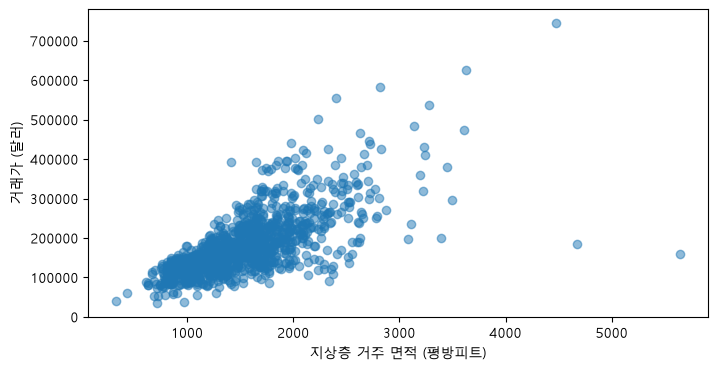

In [29]:
# [제공] 거주 면적과 거래가 (학습용 데이터)
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(train_df["GrLivArea"], train_df["SalePrice"], alpha=0.5)
ax.set_xlabel("지상층 거주 면적 (평방피트)")
ax.set_ylabel("거래가 (달러)")
plt.show()

> **[판단]** 거래가와 가장 관련이 깊어 보이는 숫자 열 세 개를 적고, 왜 그럴지 한 줄씩 설명하세요.
>
> 나의 답: ① OverallQual(전체 품질, 상관 0.79): 자재와 마감이 좋을수록 비쌉니다. 사람들이 집값을 매길 때 가장 먼저 보는 요소입니다.
> ② GrLivArea(거주 면적, 상관 0.70): 집이 넓을수록 비쌉니다. 면적은 가격의 기본 단위입니다.
> ③ GarageCars(차고 차량 수, 상관 0.64): 차고가 크다는 것은 대체로 집과 대지가 크고 최근에 지은 집이라는 뜻이라 가격과 같이 움직입니다.

> **[판단]** 산점도에서 눈에 띄는 점이 있나요? (예: 면적에 비해 값이 이상한 집) 이런 집을 모델에서 빼도 될까요, 두어야 할까요?
>
> 나의 답: 네, 면적이 4,500평방피트가 넘는 아주 큰 집 두 채(Edwards 동네)가 20만 달러도 안 되는 가격에 팔렸습니다. 둘 다 거래 조건이 Partial(공사 중 분양)이라서 정상 거래가 아닐 수 있습니다.
> 무조건 빼면 안 됩니다. 데이터 오류나 특수 거래라는 근거가 있을 때만 빼고, 빼면 그 사실을 보고서에 적어야 합니다. 이번 실습에서는 근거가 확실하지 않아서 그대로 두었습니다. 실제 서비스에도 이런 매물이 올라올 수 있기 때문입니다.

---
# Part 2. 베이스라인 고르기

강의 2-1에서 회귀의 베이스라인은 "모든 집은 평균 가격"이라고 배웠습니다. 그런데 "평균 가격"만이 유일한 선택일까요?

## 2-1. 평균 예측과 중앙값 예측

**[직접 작성]** 학습용 데이터의 거래가 **평균**과 **중앙값**을 각각 평가용 집 전체의 예측값으로 쓴 두 베이스라인을 `evaluate`로 채점하고, 결과 지표를 `m_mean`, `m_median`에 저장하세요. 이어서 두 결과를 `log_result`로 기록합니다.

<details><summary>힌트</summary>

`mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())`로 같은 값을 반복한 배열을 만듭니다. 중앙값도 같은 방식입니다.

`m_mean = evaluate("평균 예측", mean_pred)`, 그다음 `log_result("평균 예측", [], m_mean)`.
</details>

In [30]:
# 2-1. 베이스라인 두 개: "모든 집 = 평균 가격", "모든 집 = 중앙값 가격"
# np.full(개수, 값)은 같은 값을 개수만큼 반복한 배열을 만듭니다.
mean_pred = np.full(len(test_df), train_df["SalePrice"].mean())
median_pred = np.full(len(test_df), train_df["SalePrice"].median())

m_mean = evaluate("평균 예측", mean_pred)
m_median = evaluate("중앙값 예측", median_pred)

log_result("평균 예측", [], m_mean)
log_result("중앙값 예측", [], m_median)

[평균 예측] MAE 62,576 | RMSE 87,619 | R² -0.001 | MAPE 41.4%
[중앙값 예측] MAE 59,568 | RMSE 88,667 | R² -0.025 | MAPE 36.0%


> **[판단]** MAE와 RMSE에서 평균 예측과 중앙값 예측 중 어느 쪽이 더 낮은가요? 두 지표에서 결과가 다르다면, 왜 그럴지 "큰 오차를 얼마나 아프게 보는가"로 설명해 보세요.
>
> 나의 답: MAE는 중앙값 예측이 더 낮고(59,568 < 62,576), RMSE는 평균 예측이 더 낮습니다(87,619 < 88,667).
> MAE는 모든 오차를 같은 무게로 더하기 때문에 "가운데에 있는 값"인 중앙값이 유리합니다. RMSE는 오차를 제곱해서 큰 오차를 훨씬 아프게 봅니다. 평균은 비싼 집 쪽으로 조금 끌려가 있어서 비싼 집에서 생기는 큰 오차가 줄어들고, 그래서 RMSE에서는 평균이 유리합니다.

> **[판단]** 회귀 모델의 점수를 비교할 베이스라인으로는 둘 중 어느 것을 쓰겠습니까? 이유도 적으세요.
>
> 나의 답: 평균 예측을 쓰겠습니다. R²는 "평균으로만 예측했을 때보다 얼마나 나아졌나"를 재는 지표라서, 평균 예측을 기준으로 해야 R²(0이 기준)와 뜻이 맞습니다. 강의에서 배운 기본 베이스라인도 평균입니다.
> (MAE만 보고서에 쓴다면 MAE가 더 낮은 중앙값을 "더 강한 베이스라인"으로 함께 보여 주는 것도 좋습니다.)

---
# Part 3. 현행 방법 만들기: 사람의 시세 규칙

모델이 없던 시절에도 중개사들은 나름의 규칙으로 시세를 매겼습니다. 비슷한 집의 평방피트당 단가에 면적을 곱하거나, 같은 동네의 비슷한 집이 얼마에 팔렸는지 떠올리는 식입니다. 여러분이 중개사라면 **정보 두세 개**로 어떤 규칙을 만들겠습니까?

**시세 규칙**: 어떤 정보를 어떻게 쓸지 **내가 정하고**, 숫자(동네별 단가 등)는 학습용 데이터에서 계산하는 방법입니다. Chapter 1에서 배운 규칙 기반(Rule-Based) 방법의 한 예로, 모델이 이겨야 할 비교 기준이 됩니다.

## 시세 규칙을 만들 때의 약속

- 쓰는 정보는 **두세 개를 넘기지 않습니다.** 머릿속으로 계산할 수 있어야 하기 때문입니다.
- 시세 규칙에 쓰는 숫자(동네별 단가, 구간별 중앙값 등)는 **학습용 데이터에서만** 계산합니다.
- 평가용 데이터를 보고 시세 규칙을 고치지 않습니다.

## 3-1. 나의 시세 규칙 만들기

> **[판단]** 나의 시세 규칙(말로): 집의 **동네(Neighborhood)** 와 **거주 면적(GrLivArea)** 을 보고, **같은 동네 집들의 평방피트당 거래가 중앙값(단가)** 을 기준으로 가격을 정한다. (가격 = 동네 단가 × 이 집의 면적)
>
> 이 정보를 고른 근거(1-6의 어떤 결과인가): 1-6에서 동네별 거래가 중앙값이 NridgHt 약 31만 달러, MeadowV 약 9만 달러로 3배 넘게 차이 났습니다. 그리고 거주 면적은 거래가와 상관이 0.70으로 높았습니다. 중개사들이 실제로 "이 동네는 평당 얼마"라고 말하는 방식과도 같습니다.
>
> 나의 답: 동네별 단가 × 거주 면적

**[직접 작성]** 시세 규칙을 코드로 옮겨 평가용 집의 가격을 계산하고, 예측을 `rule_pred`(평가용 `test_df`와 같은 순서의 `Series`)에 저장하세요. 그다음 `evaluate`로 채점하고, 결과를 `m_rule`에 저장한 뒤 `log_result`로 기록합니다.

<details><summary>힌트</summary>

학습용 데이터에서 평방피트당 단가를 구하는 예시입니다.

```python
unit_price = (train_df["SalePrice"] / train_df["GrLivArea"]).median()
rule_pred = test_df["GrLivArea"] * unit_price
```

동네별로 단가를 다르게 쓰려면 단가를 동네별로 구한 뒤 `map`으로 붙입니다.

```python
unit_by_nb = (train_df["SalePrice"] / train_df["GrLivArea"]).groupby(train_df["Neighborhood"]).median()
rule_pred = test_df["Neighborhood"].map(unit_by_nb) * test_df["GrLivArea"]
```

이 예시는 형식만 보여 주는 것입니다. 여러분의 시세 규칙을 쓰세요. 평가용에만 있는 동네가 있을 수 있으니, 빈 값이 생기면 `fillna(train_df["SalePrice"].median())`처럼 채우세요.
</details>

In [31]:
# 3-1. 나의 시세 규칙: "같은 동네의 평방피트당 단가 × 이 집의 거주 면적"
# 단가(1평방피트에 얼마)는 학습용 데이터에서만 계산합니다.
unit_price = train_df["SalePrice"] / train_df["GrLivArea"]
unit_by_nb = unit_price.groupby(train_df["Neighborhood"]).median()   # 동네별 단가 중앙값

# 평가용 집마다 자기 동네 단가를 붙이고(map), 면적을 곱합니다.
# 학습용에 없던 동네가 나오면 전체 단가 중앙값을 씁니다.
nb_unit = test_df["Neighborhood"].map(unit_by_nb).fillna(unit_price.median())
rule_pred = nb_unit * test_df["GrLivArea"]

m_rule = evaluate("내 시세 규칙", rule_pred)
log_result("내 시세 규칙", ["Neighborhood", "GrLivArea"], m_rule)

[내 시세 규칙] MAE 31,352 | RMSE 44,506 | R² 0.742 | MAPE 18.9%


> **[판단]** 내 시세 규칙의 MAE는 베이스라인(평균·중앙값 예측)보다 얼마나 낮은가요? 정보 두세 개만으로 오차가 이만큼 줄어든다는 것은 무엇을 뜻할까요?
>
> 나의 답: 내 시세 규칙의 MAE는 31,352달러로, 평균 예측(62,576)보다 약 31,000달러(약 50%) 낮고 중앙값 예측(59,568)보다도 약 28,000달러 낮습니다.
> 정보 두 개(동네, 면적)만으로 오차가 절반으로 줄었다는 것은 집값의 큰 부분이 "어디에 있고 얼마나 넓은가"로 설명된다는 뜻입니다. 모델을 만들려면 최소한 이 간단한 규칙보다는 확실히 좋아야 의미가 있습니다.

---
# Part 4. 모델 만들기와 실험 기록

이제 모델을 만들어 내 시세 규칙과 겨룹니다. 강의 Part 2의 코드를 보지 말고 먼저 직접 써 보세요.

## 4-1. 첫 모델: 다중회귀

**[직접 작성]** 아래 순서로 작성하세요.

1. 피처 `["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]`로 `make_data`를 호출해 `X_train, X_test, y_train, y_test`를 만든다
2. `LinearRegression`을 학습한다
3. 학습용과 평가용을 모두 `evaluate`로 채점한다 (학습용은 `y_true=y_train`을 줍니다)
4. 평가용 결과를 `log_result`로 기록한다

<details><summary>힌트</summary>

강의 2-3의 코드와 같은 순서입니다.

```python
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))
log_result("다중회귀 5개", features, m_test, m_train)
```
</details>

In [32]:
# 4-1. 첫 모델: 다중회귀 (피처 5개)
features = ["GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars"]

# ① 데이터 만들기
X_train, X_test, y_train, y_test = make_data(features)

# ② 모델 학습: 각 피처에 곱할 "가중치(계수)"를 학습용 데이터로 찾습니다
model = LinearRegression()
model.fit(X_train, y_train)

# ③ 학습용·평가용 모두 채점 (둘을 비교하면 과적합을 알 수 있습니다)
m_train = evaluate("학습용", model.predict(X_train), y_true=y_train)
m_test = evaluate("다중회귀 5개", model.predict(X_test))

# ④ 기록
log_result("다중회귀 5개", features, m_test, m_train)

[학습용] MAE 24,399 | RMSE 37,970 | R² 0.758 | MAPE 14.5%
[다중회귀 5개] MAE 25,415 | RMSE 39,763 | R² 0.794 | MAPE 15.3%


> **[판단]** 이 모델의 학습용 점수와 평가용 점수는 얼마나 차이 나나요? 그 차이는 과적합의 신호일까요?
>
> 나의 답: 학습용 MAE 24,399, 평가용 MAE 25,415로 차이가 약 1,000달러(4%)뿐입니다. R²는 오히려 평가용이 더 높습니다(0.758 vs 0.794).
> 과적합의 신호가 아닙니다. 과적합이라면 학습용에서는 아주 잘 맞히고 평가용에서는 크게 틀려야 합니다. 이 모델은 피처가 5개뿐인 단순한 모델이라 오히려 "덜 배운" 쪽(과소적합)에 가깝습니다.

## 4-2. 피처와 모델을 바꿔 보기

피처를 늘리거나 모델의 복잡도를 바꿔 가며 **세 번 이상** 실험하세요. 매번 아래 `run`이 학습용·평가용 점수를 모두 채점해 기록해 줍니다.

**[직접 작성]** `run(이름, 피처 목록, 모델)`을 세 번 이상 호출하세요. 다음 세 가지를 모두 포함하면 좋습니다.

- 숫자 피처만 늘려 보기
- 범주형 피처(동네, 마감 품질 등)를 더해 보기
- 모델의 복잡도를 올려 보기 (다항 피처)와, 그에 벌점을 주는 Ridge

<details><summary>힌트</summary>

```python
run("숫자 12개", num_features, LinearRegression())
run("숫자+범주", num_features + cat_features, LinearRegression())
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))
run("3차 다항 + Ridge", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=100)))
```

`alpha`(벌점의 세기)를 10, 100, 1000으로 바꿔 보면 학습용·평가용 점수가 어떻게 달라지는지 볼 수 있습니다.
</details>

In [33]:
# 실험 1: 숫자 피처만 12개로 늘리기
run("숫자 12개", num_features, LinearRegression())

# 실험 2: 범주형(동네, 마감 품질 등)까지 더하기 (원핫 인코딩은 make_data가 해 줍니다)
run("숫자+범주", num_features + cat_features, LinearRegression())

# 실험 3: 모델을 복잡하게 → 3차 다항 피처 (피처끼리 곱한 항, 제곱·세제곱 항을 추가)
run("3차 다항", num_features, make_pipeline(StandardScaler(), PolynomialFeatures(3), LinearRegression()))

# 실험 4: 같은 3차 다항에 Ridge(계수에 벌점)를 걸어 과적합 줄이기 — 벌점 세기 alpha를 바꿔 봅니다
for a in [10, 100, 1000]:
    run(f"3차 다항 + Ridge {a}", num_features,
        make_pipeline(StandardScaler(), PolynomialFeatures(3), Ridge(alpha=a)))

[숫자 12개 (학습용)] MAE 22,972 | RMSE 36,605 | R² 0.775 | MAPE 13.7%
[숫자 12개] MAE 24,353 | RMSE 39,231 | R² 0.799 | MAPE 14.5%
[숫자+범주 (학습용)] MAE 18,428 | RMSE 29,716 | R² 0.852 | MAPE 10.6%
[숫자+범주] MAE 20,172 | RMSE 32,698 | R² 0.861 | MAPE 11.9%
[3차 다항 (학습용)] MAE 11,736 | RMSE 16,646 | R² 0.954 | MAPE 7.2%
[3차 다항] MAE 29,235 | RMSE 67,319 | R² 0.409 | MAPE 17.8%
[3차 다항 + Ridge 10 (학습용)] MAE 12,571 | RMSE 18,059 | R² 0.945 | MAPE 7.7%
[3차 다항 + Ridge 10] MAE 22,671 | RMSE 41,122 | R² 0.780 | MAPE 13.5%
[3차 다항 + Ridge 100 (학습용)] MAE 13,872 | RMSE 19,911 | R² 0.934 | MAPE 8.5%
[3차 다항 + Ridge 100] MAE 20,222 | RMSE 32,073 | R² 0.866 | MAPE 12.3%
[3차 다항 + Ridge 1000 (학습용)] MAE 17,013 | RMSE 23,963 | R² 0.904 | MAPE 10.5%
[3차 다항 + Ridge 1000] MAE 20,858 | RMSE 31,688 | R² 0.869 | MAPE 13.2%


**[제공]** 실험 기록표를 평가 MAE 순으로 봅니다.

In [34]:
# [제공] 실험 기록표
pd.DataFrame(experiment_log).sort_values("평가 MAE")

,실험,피처 수,학습 MAE,학습 RMSE,평가 MAE,평가 RMSE,평가 R²
5,숫자+범주,18,18428.0,29716.0,20172,32698,0.861
8,3차 다항 + Ridge 100,12,13872.0,19911.0,20222,32073,0.866
9,3차 다항 + Ridge 1000,12,17013.0,23963.0,20858,31688,0.869
7,3차 다항 + Ridge 10,12,12571.0,18059.0,22671,41122,0.780
4,숫자 12개,12,22972.0,36605.0,24353,39231,0.799
3,다중회귀 5개,5,24399.0,37970.0,25415,39763,0.794
6,3차 다항,12,11736.0,16646.0,29235,67319,0.409
2,내 시세 규칙,2,NaN,NaN,31352,44506,0.742
1,중앙값 예측,-,NaN,NaN,59568,88667,-0.025
0,평균 예측,-,NaN,NaN,62576,87619,-0.001


> **[판단]** 범주형 피처(동네, 마감 품질 등)를 더했을 때 오차가 얼마나 줄었나요? 이 피처들이 왜 도움이 되었을까요?
>
> 나의 답: 숫자 12개(24,353) → 숫자+범주(20,172)로 평가 MAE가 약 4,200달러(17%) 줄었고, R²도 0.799 → 0.861로 올랐습니다.
> 동네는 "같은 면적이라도 어느 동네냐에 따라 값이 다르다"는 입지 정보를 주고, 외장·주방·지하실 품질(ExterQual, KitchenQual, BsmtQual)은 숫자 피처에 없는 마감 상태 정보를 줍니다. 숫자 피처만으로는 알 수 없던 정보가 들어와서 도움이 되었습니다.

> **[판단]** 학습용 점수와 평가용 점수의 차이가 가장 큰 실험은 무엇인가요? Ridge를 쓰면 그 차이가 어떻게 달라졌나요? 강의 Part 3의 "과적합"과 "정규화"로 설명해 보세요.
>
> 나의 답: "3차 다항"이 가장 차이가 큽니다. 학습용 MAE 11,736 → 평가용 29,235, RMSE는 16,646 → 67,319로 평가용 점수가 크게 나빠졌습니다(평가 R² 0.409).
> 피처를 서로 곱하고 세제곱한 항이 수백 개 생겨 모델이 너무 복잡해졌고, 학습용 데이터의 우연한 패턴까지 외워 버린 것이 과적합입니다. Ridge로 계수에 벌점을 주자(정규화) 평가 MAE가 22,671(alpha 10) → 20,222(alpha 100)로 좋아졌고, 학습용과 평가용의 차이도 줄었습니다. alpha를 1000까지 올리면 학습용 점수는 더 나빠지지만(17,013) 평가용 차이는 가장 작아집니다. 벌점이 셀수록 모델이 단순해진다는 뜻입니다.

> **[판단]** 가장 좋은 모델은 내 시세 규칙보다 MAE가 얼마나(달러, %) 낮은가요? 이 차이라면 기획팀이 모델을 도입할 만할까요?
>
> 나의 답: 가장 좋은 모델(숫자+범주, MAE 20,172)은 내 시세 규칙(31,352)보다 약 11,200달러, 약 36% 낮습니다.
> 한 채당 평균 1만 달러 넘게 덜 틀리는 것이므로 도입할 만하다고 봅니다. 다만 비싼 집에서는 여전히 크게 틀리므로(Part 5) 모든 매물에 그대로 쓰기보다는 가격대별 주의 문구와 함께 도입하는 것이 좋겠습니다.

## 4-3. Lasso: 피처를 고르는 정규화

4-2의 Ridge는 계수를 **고르게 줄이는** 정규화였습니다. **Lasso**는 벌점의 모양이 달라서, 덜 중요한 계수를 **정확히 0**으로 만듭니다. 계수가 0인 피처는 모델에서 빠진 것과 같으므로, Lasso는 정규화이면서 동시에 피처를 고르는 방법입니다.

| | Ridge | Lasso |
| --- | --- | --- |
| 벌점 | 계수의 제곱합 | 계수의 절댓값합 |
| 계수가 줄어드는 방식 | 모두 고르게, 0이 되지는 않음 | 덜 중요한 것부터 정확히 0 |

이 절에서는 Lasso가 실제로 어떤 피처를 버리는지 세 가지 실험으로 확인합니다. 세 실험 모두 실험 기록표(`experiment_log`)에는 남기지 않습니다.

### 실험 1. 계수 비교: 무엇이 0이 되는가

**[직접 작성]** 숫자 피처 12개(`num_features`)로 세 모델을 학습하고, 계수를 한 표로 비교하세요. 세 모델 모두 `StandardScaler`를 앞에 붙입니다(표준화해야 계수끼리 비교할 수 있습니다).

- 선형회귀 (`LinearRegression()`)
- Ridge (`Ridge(alpha=100)`)
- Lasso (`Lasso(alpha=5000)`)

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # 파이프라인의 마지막 단계(모델)의 계수
pd.DataFrame(coefs, index=X_tr.columns).round(0)
```

`m[-1]`은 파이프라인의 마지막 단계, 즉 모델입니다.
</details>

In [35]:
# 4-3 실험 1. 선형회귀 · Ridge · Lasso의 계수 비교 (숫자 피처 12개)
# StandardScaler로 모든 피처의 단위를 맞춰야 계수 크기끼리 비교할 수 있습니다.
X_tr, X_te, y_tr, y_te = make_data(num_features)
coefs = {}
for name, reg in [("선형회귀", LinearRegression()), ("Ridge 100", Ridge(alpha=100)), ("Lasso 5000", Lasso(alpha=5000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coefs[name] = m[-1].coef_          # m[-1] = 파이프라인의 마지막 단계(모델)
pd.DataFrame(coefs, index=X_tr.columns).round(0)

,선형회귀,Ridge 100,Lasso 5000
GrLivArea,21092.0,16753.0,19576.0
OverallQual,26459.0,23642.0,27385.0
YearBuilt,8745.0,8074.0,5089.0
YearRemodAdd,7366.0,7685.0,4259.0
TotalBsmtSF,6347.0,6859.0,5948.0
GarageCars,7082.0,6667.0,6992.0
GarageArea,3930.0,5248.0,3068.0
LotArea,6052.0,5598.0,2517.0
FullBath,-3116.0,-790.0,0.0
TotRmsAbvGrd,1805.0,4033.0,0.0


> **[판단]** Lasso가 0으로 만든 피처는 무엇인가요? 그 피처들은 집값과 정말 관계가 없을까요? 1-6의 상관표나 다른 피처와의 관계를 떠올려 설명해 보세요.
>
> 나의 답: FullBath(욕실 수)와 TotRmsAbvGrd(방 수)가 0이 되었습니다.
> 관계가 없는 것은 아닙니다. 1-6에서 둘 다 거래가와 상관이 0.5 이상이었습니다. 하지만 욕실 수와 방 수는 거주 면적(GrLivArea)이 크면 같이 늘어나는 정보라, 면적이 이미 들어 있으면 새로 알려 주는 것이 거의 없습니다. Lasso는 이렇게 겹치는 정보 중 덜 중요한 것을 0으로 만들어 버립니다. 그래서 "0 = 집값과 무관"이 아니라 "다른 피처가 이미 설명하고 있음"으로 읽어야 합니다.

### 실험 2. 잡음 피처를 섞으면

**[제공]** 아무 의미 없는 무작위 숫자 열 5개(`noise0`~`noise4`)를 데이터에 추가합니다. 집값과 전혀 관계가 없는 열입니다.

In [36]:
# [제공] 무작위 잡음 피처 5개 추가 (씨앗 고정)
rng = np.random.RandomState(0)
noise_features = [f"noise{i}" for i in range(5)]
for col in noise_features:
    df[col] = rng.randn(len(df))
print(df[noise_features].describe().round(2).loc[["mean", "std"]])

      noise0  noise1  noise2  noise3  noise4
mean   -0.02   -0.03   -0.02    0.02   -0.02
std     0.98    0.96    1.01    0.99    0.99


**[직접 작성]** `num_features + noise_features`로 선형회귀와 Lasso(`alpha=1000`)를 학습하세요. 각 모델에서

1. 잡음 피처 5개의 계수
2. 계수가 정확히 0이 된 피처 목록
3. 평가용 점수 (`evaluate`로 채점)

를 출력합니다.

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)
m = make_pipeline(StandardScaler(), Lasso(alpha=1000)).fit(X_tr, y_tr)
coef = pd.Series(m[-1].coef_, index=X_tr.columns)
print(coef[noise_features].round(0))
print("0이 된 피처:", list(coef[coef == 0].index))
evaluate("Lasso + 잡음", m.predict(X_te))
```
</details>

In [37]:
# 4-3 실험 2. 잡음 피처 5개를 섞었을 때 선형회귀 vs Lasso
X_tr, X_te, y_tr, y_te = make_data(num_features + noise_features)

for name, reg in [("선형회귀 + 잡음", LinearRegression()), ("Lasso 1000 + 잡음", Lasso(alpha=1000))]:
    m = make_pipeline(StandardScaler(), reg).fit(X_tr, y_tr)
    coef = pd.Series(m[-1].coef_, index=X_tr.columns)
    print(f"===== {name} =====")
    print("잡음 피처의 계수:")
    print(coef[noise_features].round(0).to_string())
    print("계수가 정확히 0이 된 피처:", list(coef[coef == 0].index))
    evaluate(name, m.predict(X_te))
    print()

===== 선형회귀 + 잡음 =====
잡음 피처의 계수:
noise0   -696.0
noise1    497.0
noise2   -144.0
noise3   -732.0
noise4   -175.0
계수가 정확히 0이 된 피처: []
[선형회귀 + 잡음] MAE 24,300 | RMSE 39,230 | R² 0.799 | MAPE 14.5%

===== Lasso 1000 + 잡음 =====
잡음 피처의 계수:
noise0   -0.0
noise1    0.0
noise2    0.0
noise3   -0.0
noise4   -0.0
계수가 정확히 0이 된 피처: ['FullBath', 'noise0', 'noise1', 'noise2', 'noise3', 'noise4']
[Lasso 1000 + 잡음] MAE 24,184 | RMSE 39,522 | R² 0.796 | MAPE 14.3%



> **[판단]** 선형회귀는 잡음 피처에 어떤 계수를 주었나요? 이 계수표만 보고 보고서를 쓰면 어떤 오해가 생길까요? Lasso는 잡음을 어떻게 다뤘고, 평가용 점수는 어떻게 달라졌나요?
>
> 나의 답: 선형회귀는 잡음 피처에 -732~+497달러 같은 0이 아닌 계수를 주었습니다. 이 계수표만 보면 "noise3이 1단위 오르면 집값이 732달러 내려간다"처럼 의미 없는 열을 의미 있는 요인으로 오해할 수 있습니다.
> Lasso(alpha=1000)는 잡음 5개의 계수를 모두 정확히 0으로 만들어 스스로 걸러 냈습니다(FullBath도 0). 평가용 점수는 MAE 24,300 → 24,184로 거의 같았습니다. 잡음 열이 5개뿐이라 점수 차이는 작지만, 해석할 수 있는 계수를 남겼다는 점이 장점입니다.

### 실험 3. 범주형까지 넣은 모델에 Lasso를 걸면

**[직접 작성]** 4-2에서 가장 좋았던 피처 조합(`num_features + cat_features`, 원핫 인코딩 후 열 67개)에 Lasso를 걸고, `alpha`를 100, 300, 1000, 3000으로 바꿔 가며 다음을 표로 정리하세요.

- 0이 아닌 계수의 수
- 평가용 MAE와 RMSE

<details><summary>힌트</summary>

```python
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a, "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)
```

비교 기준은 실험 기록표의 "숫자+범주"(선형회귀) 줄입니다.
</details>

In [38]:
# 4-3 실험 3. 숫자+범주(원핫 후 67열)에 Lasso, alpha를 바꿔 가며
X_tr, X_te, y_tr, y_te = make_data(num_features + cat_features)
print("전체 열 수:", X_tr.shape[1])
rows = []
for a in [100, 300, 1000, 3000]:
    m = make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=100000)).fit(X_tr, y_tr)
    p = m.predict(X_te)
    rows.append({"alpha": a,
                 "남은 피처 수": int((m[-1].coef_ != 0).sum()),
                 "평가 MAE": round(mean_absolute_error(y_te, p)),
                 "평가 RMSE": round(np.sqrt(mean_squared_error(y_te, p)))})
pd.DataFrame(rows)

전체 열 수: 67


,alpha,남은 피처 수,평가 MAE,평가 RMSE
0,100,58,20090,32704
1,300,48,20030,32767
2,1000,34,19946,33056
3,3000,24,20717,34903


> **[판단]** Lasso는 "숫자+범주" 선형회귀보다 나아졌나요? MAE와 RMSE가 같은 방향으로 움직였나요? 4-2의 3차 다항 실험에서 Ridge가 큰 효과를 냈던 것과 비교해, 여기서 효과가 작은 이유를 "이 모델이 과적합했는가"로 설명해 보세요.
>
> 나의 답: 조금 나아졌지만 거의 비슷합니다. "숫자+범주" 선형회귀의 MAE 20,172 → Lasso alpha 1000에서 19,946으로 약 1% 줄었습니다. 그런데 RMSE는 32,698 → 33,056으로 오히려 늘어서 두 지표가 반대로 움직였습니다. 평균적인 오차는 줄었지만 큰 오차는 조금 커졌다는 뜻입니다.
> 효과가 작은 이유는 이 모델이 애초에 과적합하지 않았기 때문입니다(학습 MAE 18,428 vs 평가 20,172로 차이가 작음). 3차 다항 모델은 심하게 과적합해서 정규화로 고칠 것이 많았지만, 여기서는 줄일 과적합이 별로 없습니다.

> **[판단]** 기획팀이 "피처를 절반만 써도 비슷하다면 더 단순한 모델이 낫지 않나요?"라고 묻습니다. 어떻게 답하겠습니까?
>
> 나의 답: "맞습니다. 이 결과에서는 피처를 67개에서 34개로 절반 가까이 줄여도 평균 오차가 거의 같았습니다(20,172 → 19,946달러). 정확도가 같다면 단순한 모델이 설명하기 쉽고, 입력해야 할 정보가 적고, 고장 날 곳도 적어서 더 낫습니다.
> 다만 큰 오차(RMSE)는 조금 늘었으니 비싼 집에서 더 틀리지 않는지 확인하고, 한 번의 데이터 나누기 결과라 다른 데이터에서도 비슷한지 확인한 뒤 결정하겠습니다."라고 답하겠습니다.

---
# Part 5. 오차 들여다보기와 보고

지표 하나로는 "믿어도 되는 집"과 "믿으면 안 되는 집"을 구분할 수 없습니다. 오차가 어디에 몰려 있는지 직접 봅니다.

## 5-1. 가격대별 오차

**[직접 작성]** 기록표에서 평가 MAE가 가장 낮은 실험을 골라 그 이름을 `best_name`에 저장하고, 그 실험의 예측을 `best_pred`에 저장하세요. 그다음 `error_by_price`로 **내 시세 규칙**과 **최고 모델**의 가격대별 오차를 각각 출력합니다.

<details><summary>힌트</summary>

모든 실험의 예측은 `preds`에 이름으로 저장되어 있습니다. `best_name = "숫자+범주"`처럼 이름을 직접 적고 `best_pred = preds[best_name]`로 꺼내세요.

`error_by_price(preds["내 시세 규칙"])`, `error_by_price(best_pred)`
</details>

In [39]:
# 5-1. 가격대별 오차
# 기록표(experiment_log)에서 평가 MAE가 가장 낮은 실험 이름을 자동으로 고릅니다.
best_name = pd.DataFrame(experiment_log).sort_values("평가 MAE").iloc[0]["실험"]
best_pred = preds[best_name]
print("최고 모델:", best_name)

print("\n[내 시세 규칙] 가격대별 오차")
display(error_by_price(preds["내 시세 규칙"]))
print(f"[최고 모델: {best_name}] 가격대별 오차")
display(error_by_price(best_pred))

최고 모델: 숫자+범주

[내 시세 규칙] 가격대별 오차


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,23931.0,-9634.0
"(100000, 200000]",184,24474.0,-5211.0
"(200000, 300000]",58,39215.0,-3082.0
"(300000, 500000]",21,57605.0,41787.0
"(500000, 800000]",3,181684.0,181684.0


[최고 모델: 숫자+범주] 가격대별 오차


,집 수,MAE,평균 편향(실제−예측)
SalePrice,,,
"(0, 100000]",26,20945.0,-14409.0
"(100000, 200000]",184,13752.0,-2168.0
"(200000, 300000]",58,24376.0,3782.0
"(300000, 500000]",21,38577.0,25190.0
"(500000, 800000]",3,197086.0,197086.0


> **[판단]** 어느 가격대에서 오차(MAE)가 가장 큰가요? 그 가격대의 "평균 편향"은 양수(실제가 더 비쌈)인가요, 음수인가요? 모델과 시세 규칙이 같은 방향으로 틀리나요?
>
> 나의 답: 두 방법 모두 50만 달러 넘는 집에서 MAE가 가장 큽니다(모델 197,086, 시세 규칙 181,684). 그다음은 30만~50만 달러 구간입니다.
> 그 가격대의 평균 편향은 양수입니다(모델 +197,086, 시세 규칙 +181,684). 실제 가격이 예측보다 훨씬 높다는 뜻으로, 비싼 집을 너무 싸게 예측합니다. 반대로 10만 달러 이하 집은 둘 다 음수(비싸게 예측)입니다. 즉 모델과 시세 규칙이 같은 방향으로 틀립니다. 가격을 가운데(평균) 쪽으로 끌어당기는 습관이 둘 다 있습니다.

## 5-2. 잔차 그림

**[직접 작성]** 최고 모델의 잔차(실제 − 예측)를 예측 가격에 대해 산점도로 그리세요. 0을 나타내는 가로선도 함께 그립니다.

<details><summary>힌트</summary>

강의 2-7의 코드와 같습니다.

```python
residual = y_test - best_pred
plt.scatter(best_pred, residual, alpha=0.5)
plt.axhline(0, color="gray")
```
</details>

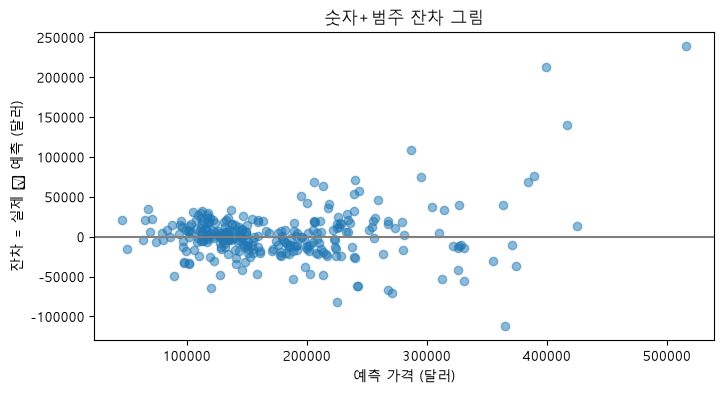

In [40]:
# 5-2. 잔차 그림: 잔차 = 실제 - 예측 (양수면 모델이 싸게 예측, 음수면 비싸게 예측)
residual = y_test - best_pred
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(best_pred, residual, alpha=0.5)
ax.axhline(0, color="gray")           # 0선: 여기에 가까울수록 잘 맞힌 집
ax.set_xlabel("예측 가격 (달러)")
ax.set_ylabel("잔차 = 실제 - 예측 (달러)")
ax.set_title(f"{best_name} 잔차 그림")
plt.show()

> **[판단]** 잔차 그림에서 규칙이 보이나요? 예측 가격이 높은 쪽에서 점들이 어떻게 흩어져 있나요?
>
> 나의 답: 규칙이 보입니다. 예측 가격이 낮은 쪽(10만~20만 달러)에서는 점들이 0선 근처에 촘촘히 모여 있는데, 예측 가격이 높아질수록 점들이 위아래로 넓게 퍼집니다(깔때기 모양).
> 특히 예측 가격이 높은 쪽에서는 0선보다 한참 위에 있는 점(실제가 훨씬 비쌈)이 여러 개 있습니다. 비싼 집일수록 오차가 커지고, 싸게 예측하는 경향이 있다는 뜻입니다.

## 5-3. 가장 크게 틀린 집 들여다보기

**[직접 작성]** 최고 모델이 가장 크게 틀린 집 10채를 골라 실제 거래가, 예측 가격, 면적(`GrLivArea`), 품질(`OverallQual`), 동네(`Neighborhood`)를 한 표로 출력하세요.

<details><summary>힌트</summary>

`test_df.assign(예측=best_pred, 오차=y_test - best_pred)`로 열을 붙인 뒤, 오차의 절댓값으로 정렬합니다. `sort_values("오차", key=abs, ascending=False).head(10)`.
</details>

In [41]:
# 5-3. 가장 크게 틀린 집 10채
worst = (test_df.assign(예측=best_pred.round(0), 오차=(y_test - best_pred).round(0))
         .sort_values("오차", key=abs, ascending=False)     # 오차의 절댓값이 큰 순
         .head(10))
worst[["SalePrice", "예측", "오차", "GrLivArea", "OverallQual", "Neighborhood"]]

,SalePrice,예측,오차,GrLivArea,OverallQual,Neighborhood
691,755000,516019.0,238981.0,4316,10,NoRidge
898,611657,398955.0,212702.0,2364,9,NridgHt
1046,556581,417006.0,139575.0,2868,9,StoneBr
581,253293,365415.0,-112122.0,2042,8,NridgHt
774,395000,286980.0,108020.0,1973,8,NridgHt
588,143000,225154.0,-82154.0,1473,5,ClearCr
1243,465000,389555.0,75445.0,2076,10,NridgHt
585,369900,295269.0,74631.0,2028,8,Timber
218,311500,240172.0,71328.0,1954,7,Crawfor
1173,200500,270721.0,-70221.0,3086,5,ClearCr


> **[판단]** 크게 틀린 집들에게 공통점이 있나요? 기획팀이 "이런 매물에는 자동 시세를 쓰지 말자"고 한다면 어떤 기준(가격대, 품질 등)을 제안하겠습니까?
>
> 나의 답: 공통점이 있습니다. 10채 중 7채는 실제 거래가가 30만 달러 이상이고, 7채는 품질 8~10등급이며, 6채는 NridgHt·NoRidge·StoneBr 같은 고급 동네에 있습니다. 상위 3채는 모두 실제보다 14만~24만 달러 싸게 예측됐습니다.
> 제안 기준: ① 품질 등급(OverallQual) 9 이상, 또는 ② 모델 예측가가 30만 달러 이상인 매물은 자동 시세 대신 "전문가 감정 필요"로 표시합니다. 실제 거래가는 등록할 때 모르므로 기준은 예측가와 품질처럼 미리 알 수 있는 정보로 정해야 합니다.

## 5-4. 가격 맞히기

곧 다른 수강생들의 결과와 함께 비교합니다. 그 전에 **사람의 감**으로 세 채의 가격을 먼저 맞혀 봅니다.

**[제공]** 평가용 집 세 채의 정보를 보여 줍니다. (거래가는 보여 주지 않습니다.)

In [42]:
# [제공] 맞혀 볼 집 세 채 (거래가는 숨김)
_s = test_df.sort_values("SalePrice")
guess_ids = [_s.index[int(q * (len(_s) - 1))] for q in (0.05, 0.5, 0.99)]
show_cols = ["Neighborhood", "GrLivArea", "OverallQual", "YearBuilt", "TotalBsmtSF", "GarageCars", "KitchenQual"]
test_df.loc[guess_ids, show_cols]

,Neighborhood,GrLivArea,OverallQual,YearBuilt,TotalBsmtSF,GarageCars,KitchenQual
649,MeadowV,630,4,1970,630,0,TA
1299,NAmes,1246,5,1959,1246,1,Gd
1243,NridgHt,2076,10,2006,2076,3,Ex


**[직접 작성]** 위 표만 보고, 세 집의 거래가를 직관으로 적으세요. (`my_guess`의 0을 달러 숫자로 바꿉니다.)

In [43]:
# 위 표의 순서대로 세 집의 거래가(달러)를 적으세요
# 근거: 1-6의 동네별 중앙값(MeadowV 약 9만, NAmes 약 14만, NridgHt 약 31만)에서 출발해
#       작은 집·차고 없음은 깎고, 품질 10등급 신축은 더 올렸습니다.
my_guess = {guess_ids[0]: 75000, guess_ids[1]: 140000, guess_ids[2]: 380000}

**[제공]** 실제 거래가를 공개합니다. 내 감, 내 시세 규칙, 최고 모델의 예측을 나란히 봅니다.

In [44]:
# [제공] 정답 공개
reveal = pd.DataFrame({
    "실제 거래가": y_test.loc[guess_ids],
    "내 감": pd.Series(my_guess),
    "내 시세 규칙": preds["내 시세 규칙"].loc[guess_ids],
    "최고 모델": best_pred.loc[guess_ids],
})
for col in ["내 감", "내 시세 규칙", "최고 모델"]:
    reveal[col + " 오차"] = (reveal[col] - reveal["실제 거래가"]).abs()
reveal.round(0)

,실제 거래가,내 감,내 시세 규칙,최고 모델,내 감 오차,내 시세 규칙 오차,최고 모델 오차
649,84500,75000,56135.0,79394.0,9500,28365.0,5106.0
1299,154000,140000,150036.0,140022.0,14000,3964.0,13978.0
1243,465000,380000,326709.0,389555.0,85000,138291.0,75445.0


> **[판단]** 세 방법(내 감, 내 시세 규칙, 모델) 중 가장 가까웠던 것은 무엇인가요? 가장 비싼 집에서는 어땠나요? 5-1의 결과와 연결해서 설명해 보세요.
>
> 나의 답: 싼 집(84,500달러)은 최고 모델(오차 5,106)이, 중간 집(154,000달러)은 내 시세 규칙(오차 3,964)이 가장 가까웠습니다. 내 감은 동네 중앙값을 기준으로 잡아서 오차 9,500, 14,000달러로 나쁘지 않았습니다.
> 가장 비싼 집(465,000달러)은 세 방법이 모두 크게 빗나갔고 모두 싸게 예측했습니다(내 감 -85,000, 시세 규칙 -138,291, 모델 -75,445). 5-1에서 본 "비싼 집일수록 크게, 싸게 틀린다"는 결과와 같습니다. 이런 집은 데이터가 적고 고급 마감 같은 추가 가치가 숫자로 잘 안 잡히기 때문입니다.

## 5-5. 먼저 예상하기

결과를 보기 전에 예상을 적어 두고, 결과를 본 뒤 비교합니다. 틀려도 괜찮습니다. 예상이 빗나간 지점이 가장 많이 배우는 곳입니다.

시세 규칙은 나의 시세 규칙 하나만 있는 것이 아닙니다. 다른 정보를 골랐다면 결과도 달랐을 것입니다. 다음 절에서는 아래 **후보 정보 5개** 중 1개 또는 2개를 고르고, **계산법 2가지** 중 하나를 쓰는 시세 규칙을 **모두** 만들어 채점합니다. 정보 조합 5 + 10 = 15가지 × 계산법 2가지 = **30개**입니다.

| 후보 정보 | 나누는 방법 |
| --- | --- |
| 동네 (`Neighborhood`) | 동네 이름 그대로 |
| 품질 등급 (`OverallQual`) | 1~10 등급 그대로 |
| 거주 면적 (`GrLivArea`) | 학습용 기준 5구간 (집 수가 같도록) |
| 건축 연도 (`YearBuilt`) | 학습용 기준 5구간 (집 수가 같도록) |
| 차고 차량 수 (`GarageCars`) | 0~4대 그대로 |

| 계산법 | 뜻 |
| --- | --- |
| (가) 그룹 중앙값 | 같은 그룹 집들의 거래가 중앙값을 그대로 시세로 쓴다 |
| (나) 그룹 단가 × 면적 | 같은 그룹 집들의 평방피트당 단가 중앙값에 그 집의 거주 면적을 곱한다 |

예: "동네 + 품질 등급, (가)"는 "같은 동네·같은 품질 등급 집들의 거래가 중앙값"을 시세로 쓰는 규칙입니다. 모든 그룹의 숫자는 학습용 데이터에서만 계산합니다.

> **[판단]** 예상 ① 기록표에서 가장 좋은 모델(평가 MAE 약 20,000달러)은 시세 규칙 30개 중 몇 개보다 MAE가 낮을까요?
>
> 나의 답: 30개 중 25개 정도보다는 낮을 것 같습니다. 정보를 2개 쓰는 좋은 규칙 몇 개는 모델과 비슷할 수도 있다고 생각합니다.

> **[판단]** 예상 ② 30개 중 MAE가 가장 낮은 시세 규칙은 어떤 정보를 쓰고, 어떤 계산법일까요? 이유도 적어 보세요.
>
> 나의 답: "동네 + 면적 구간, (나) 그룹 단가 × 면적"일 것 같습니다. 1-6에서 동네별 가격 차이가 3배 넘게 났고, 면적은 가격과 상관이 높습니다. 그리고 단가에 면적을 곱하면 같은 그룹 안에서도 넓은 집을 더 비싸게 매길 수 있기 때문입니다.

## 5-6. 시세 규칙 30개 채점하기

**[직접 작성]** `my_rule_text`에 나의 시세 규칙을 한 줄로 적으세요. 아래 결과에서 나의 시세 규칙을 표시할 때 씁니다. (예: `"동네별 평방피트당 단가 × 거주 면적"`)

In [45]:
my_rule_text = "동네별 평방피트당 단가 × 거주 면적"

**[제공]** 후보 정보 5개 중 1~2개 × 계산법 2가지로 시세 규칙 30개를 만들고, 평가용 데이터에서 채점합니다.

In [46]:
# [제공] 시세 규칙 30개 만들기
from itertools import combinations

def train_bins(col, q=5):
    """학습용 데이터로 집 수가 같은 q개 구간의 경계를 정하고, 그 경계로 학습용·평가용을 나눕니다."""
    edges = np.unique(np.quantile(train_df[col], np.linspace(0, 1, q + 1)))
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(train_df[col], edges).astype(str), pd.cut(test_df[col], edges).astype(str)

groupers = {
    "동네": (train_df["Neighborhood"].astype(str), test_df["Neighborhood"].astype(str)),
    "품질 등급": (train_df["OverallQual"].astype(str), test_df["OverallQual"].astype(str)),
    "면적 구간": train_bins("GrLivArea"),
    "연도 구간": train_bins("YearBuilt"),
    "차고": (train_df["GarageCars"].astype(str), test_df["GarageCars"].astype(str)),
}
price_tr = train_df["SalePrice"]
unit_tr = train_df["SalePrice"] / train_df["GrLivArea"]

rows = []
for n in [1, 2]:
    for combo in combinations(groupers, n):
        key_tr = groupers[combo[0]][0].copy()
        key_te = groupers[combo[0]][1].copy()
        for c in combo[1:]:
            key_tr = key_tr + " | " + groupers[c][0]
            key_te = key_te + " | " + groupers[c][1]
        # (가) 그룹 중앙값
        med = price_tr.groupby(key_tr).median()
        pred_a = key_te.map(med).fillna(price_tr.median())
        # (나) 그룹 단가 × 면적
        unit = unit_tr.groupby(key_tr).median()
        pred_b = key_te.map(unit).fillna(unit_tr.median()) * test_df["GrLivArea"]
        for method, pred in [("(가) 그룹 중앙값", pred_a), ("(나) 그룹 단가 × 면적", pred_b)]:
            err = (test_df["SalePrice"] - pred).abs()
            rows.append({"정보": " + ".join(combo), "정보 수": n, "계산법": method, "평가 MAE": float(err.mean())})

rules = pd.DataFrame(rows).sort_values("평가 MAE", ignore_index=True)
print("만든 시세 규칙 수:", len(rules))
rules.head(10).round(0)

만든 시세 규칙 수: 30


,정보,정보 수,계산법,평가 MAE
0,품질 등급 + 면적 구간,2,(나) 그룹 단가 × 면적,25031.0
1,품질 등급 + 면적 구간,2,(가) 그룹 중앙값,26569.0
2,동네 + 면적 구간,2,(나) 그룹 단가 × 면적,26712.0
3,동네 + 면적 구간,2,(가) 그룹 중앙값,26821.0
4,동네 + 품질 등급,2,(가) 그룹 중앙값,27599.0
5,품질 등급 + 차고,2,(가) 그룹 중앙값,28281.0
6,품질 등급 + 연도 구간,2,(가) 그룹 중앙값,29385.0
7,면적 구간 + 차고,2,(나) 그룹 단가 × 면적,29402.0
8,동네 + 품질 등급,2,(나) 그룹 단가 × 면적,29580.0
9,면적 구간 + 연도 구간,2,(나) 그룹 단가 × 면적,29676.0


**[제공]** 가장 좋은 모델과 나의 시세 규칙이 30개 규칙 사이에서 어디쯤인지 봅니다.

가장 좋은 모델 [숫자+범주] 평가 MAE 20,172
  MAE로 이기는 시세 규칙: 30개 / 30개
나의 시세 규칙 [동네별 평방피트당 단가 × 거주 면적] 평가 MAE 31,352
  30개 중 나보다 MAE가 낮은 시세 규칙: 15개

정보 수 × 계산법별 MAE 중앙값
계산법   (가) 그룹 중앙값  (나) 그룹 단가 × 면적
정보 수                            
1        39265.0         32983.0
2        30329.0         29749.0


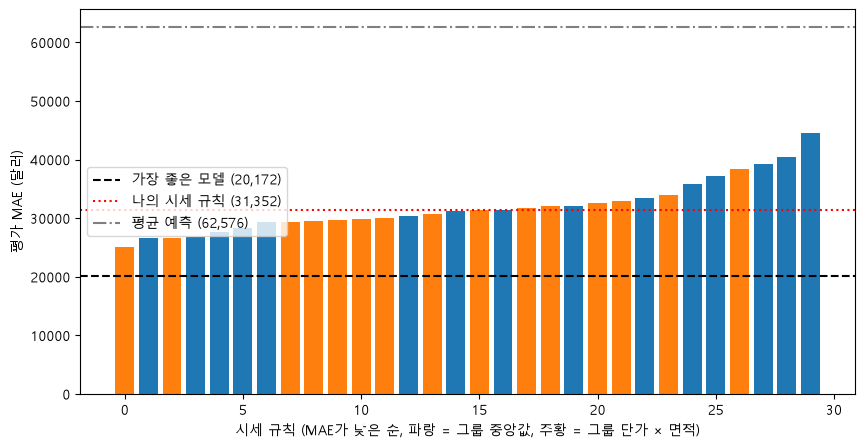

In [47]:
# [제공] 모델과 나의 시세 규칙의 위치
_log = pd.DataFrame(experiment_log)
_models = _log[_log["학습 MAE"].notna()]
_best = _models.sort_values("평가 MAE", kind="stable").iloc[0]
best_mae = float(_best["평가 MAE"])
my_mae = float(m_rule["MAE"])

print(f"가장 좋은 모델 [{_best['실험']}] 평가 MAE {best_mae:,.0f}")
print(f"  MAE로 이기는 시세 규칙: {(rules['평가 MAE'] > best_mae).sum()}개 / {len(rules)}개")
print(f"나의 시세 규칙 [{my_rule_text}] 평가 MAE {my_mae:,.0f}")
print(f"  30개 중 나보다 MAE가 낮은 시세 규칙: {(rules['평가 MAE'] < my_mae).sum()}개")
print()
print("정보 수 × 계산법별 MAE 중앙값")
print(rules.pivot_table(index="정보 수", columns="계산법", values="평가 MAE", aggfunc="median").round(0))

fig, ax = plt.subplots(figsize=(10, 5))
colors = rules["계산법"].map({"(가) 그룹 중앙값": "tab:blue", "(나) 그룹 단가 × 면적": "tab:orange"})
ax.bar(range(len(rules)), rules["평가 MAE"], color=colors)
ax.axhline(best_mae, color="black", linestyle="--", label=f"가장 좋은 모델 ({best_mae:,.0f})")
ax.axhline(my_mae, color="red", linestyle=":", label=f"나의 시세 규칙 ({my_mae:,.0f})")
ax.axhline(m_mean["MAE"], color="gray", linestyle="-.", label=f"평균 예측 ({m_mean['MAE']:,.0f})")
ax.set_xlabel("시세 규칙 (MAE가 낮은 순, 파랑 = 그룹 중앙값, 주황 = 그룹 단가 × 면적)")
ax.set_ylabel("평가 MAE (달러)")
ax.legend(loc="center left")
plt.show()

## 5-7. 결과를 본 뒤

> **[판단]** 예상 ①, ②는 맞았나요? 가장 크게 빗나간 것은 무엇이고, 왜 빗나갔다고 생각하나요?
>
> 나의 답: 예상 ①은 빗나갔습니다. 25개 정도라고 했는데 실제로는 모델이 30개 전부보다 MAE가 낮았습니다. 가장 좋은 시세 규칙(25,031)과 모델(20,172)의 차이도 약 5,000달러로 생각보다 컸습니다. 모델은 여러 정보를 한꺼번에, 각자 알맞은 무게로 쓰지만 시세 규칙은 정보 2개로 그룹을 나누는 것이 전부라 한계가 있었습니다.
> 예상 ②는 절반만 맞았습니다. 계산법 (나)와 면적 구간은 맞았지만, 1등은 "품질 등급 + 면적 구간"이었고 "동네 + 면적 구간"은 3등이었습니다. 1-6에서 거래가와 가장 상관이 높았던 것이 품질 등급(0.79)이었다는 점을 놓쳤습니다.

> **[판단]** 정보를 1개 쓴 규칙과 2개 쓴 규칙, 계산법 (가)와 (나) 중 어느 쪽의 MAE가 대체로 낮은가요? 계산법 (나)가 유리하거나 불리한 경우는 어떤 정보를 쓸 때인지도 표에서 찾아 보세요.
>
> 나의 답: 정보를 2개 쓴 규칙이 대체로 낮습니다. (가)의 중앙값이 39,265 → 30,329, (나)는 32,983 → 29,749로 줄었습니다. 계산법은 (나) 그룹 단가 × 면적이 대체로 낮습니다.
> (나)는 그룹을 나눌 때 면적을 쓰지 않을 때 특히 유리합니다. 정보 1개 기준으로 동네만 쓸 때 (가) 37,203 → (나) 31,352, 연도만 쓸 때 44,472 → 32,983으로 크게 좋아졌습니다. 면적이 따로 반영되기 때문입니다. 반대로 품질 등급과 함께 쓸 때는 (나)가 불리합니다. 품질 등급 1개는 (가) 30,326 < (나) 32,665이고, 동네+품질 등급과 품질 등급+차고도 (가)가 낫습니다. 고급 집일수록 단가 자체가 다르고 면적과 단가가 일정하게 비례하지 않아서 그렇다고 생각합니다.

> **[판단]** 가장 좋은 시세 규칙과 가장 좋은 모델의 MAE 차이는 얼마인가요? 이 차이와, 시세 규칙은 누구나 이해하고 바로 쓸 수 있다는 점을 함께 놓고 보면 기획팀에 무엇을 권하겠습니까?
>
> 나의 답: 가장 좋은 시세 규칙(품질 등급 + 면적 구간, (나))은 MAE 25,031, 가장 좋은 모델은 20,172로 약 4,900달러(약 19%) 차이입니다.
> 기획팀에는 모델을 권하겠습니다. 매물 한 채마다 평균 5,000달러 가까이 더 정확하고, 이 서비스의 목적이 "실제 거래가와 너무 다르지 않은 시세"이기 때문입니다. 다만 사용자에게 근거를 설명할 때는 "같은 품질·비슷한 면적 집의 평방피트당 단가" 같은 시세 규칙을 함께 보여 주면 이해하기 쉽고 믿음을 줄 수 있습니다. 모델에 문제가 생겼을 때 대신 쓸 예비 방법으로도 시세 규칙을 남겨 두면 좋습니다.

> **[판단]** 나의 시세 규칙은 30개 사이에서 어디쯤인가요? 정보를 하나 더하거나 계산법을 바꾼다면 어떤 규칙을 고르겠습니까? 위 표에서 그 규칙을 찾아 결과를 적어 보세요.
>
> 나의 답: 나의 시세 규칙(동네 + 단가 × 면적, MAE 31,352)은 30개 중 16등입니다. 나보다 MAE가 낮은 규칙이 15개라 딱 중간쯤입니다.
> 정보를 하나 더한다면 "품질 등급"을 더하겠습니다. 다만 표를 보면 동네 + 품질 등급은 (나) 계산법일 때 29,580이고, 계산법을 (가) 그룹 중앙값으로 바꾸면 27,599로 더 좋아집니다. 단가 계산을 고집하겠다면 동네 대신 품질 등급과 면적 구간으로 그룹을 나눈 (나) 규칙(25,031, 1등)을 고르겠습니다.

## 5-6. 기획팀 보고 메모

분석 결과를 기획팀장에게 메시지로 보낸다고 생각하고 쓰세요. 팀장은 머신러닝 용어를 모릅니다. 아래 네 가지가 모두 들어가야 합니다.

1. **오차를 어떤 지표로 말할 것인가**: MAE와 RMSE 중 하나를 고르고, 의뢰서의 문장("너무 다르면 플랫폼을 믿지 않게 된다")에 근거해 이유를 쓴다. "평균적으로 ±얼마"를 달러로 적는다.
2. **지금 쓰는 방법(내 시세 규칙)과 비교해 얼마나 나은가**
3. **믿어도 되는 집과 믿으면 안 되는 집**: 5-1의 가격대별 오차에 근거해 구분 기준을 제안한다.
4. **주의할 점**: 1-4의 빈 값 처리 결정, 데이터의 한계(Ames 한 도시의 2006~2010년 거래), 아직 확인하지 못한 것

> **[판단]** 기획팀 보고 메모:
>
> 1. 오차 지표와 ±얼마: 평균 오차(MAE)로 말씀드리겠습니다. 저희 시세는 실제 거래가와 **평균적으로 약 ±2만 달러(20,172달러), 비율로는 약 ±12%** 차이 납니다. 의뢰서에서 걱정하신 것은 "시세가 실제와 너무 달라 신뢰를 잃는 것"이고, 이는 몇 채의 극단값보다 대부분의 매물에서 느끼는 일상적인 차이의 문제라서 그대로 읽을 수 있는 MAE가 알맞습니다. 다만 크게 틀리는 경우를 따로 관리해야 하므로 3번에서 기준을 함께 제안합니다.
>
> 2. 시세 규칙과의 비교: 현재 방식(동네별 평방피트당 단가 × 면적)은 평균 약 31,000달러 틀립니다. 모델은 이보다 **한 채당 약 11,000달러(36%) 더 정확**합니다. 품질과 면적으로 만들 수 있는 가장 좋은 규칙(평균 오차 25,000달러)과 비교해도 약 5,000달러 더 정확합니다.
>
> 3. 믿어도 되는 집 / 믿으면 안 되는 집: **10만~20만 달러 집(전체의 약 63%)은 평균 오차가 약 14,000달러**로 믿고 쓸 만합니다. 반면 **30만 달러 이상 집은 평균 4만~20만 달러씩 틀리고, 거의 항상 실제보다 싸게** 나옵니다. 그래서 예측가가 30만 달러 이상이거나 품질 등급 9~10인 고급 매물은 자동 시세를 보여 주지 말고 "전문가 감정 권장"으로 표시하기를 제안합니다. 10만 달러 이하 저가 주택은 반대로 조금 비싸게 나오는 경향이 있으니 참고 범위로만 보여 주는 것이 좋습니다.
>
> 4. 주의할 점: ① 지하실·차고 품질 같은 항목이 비어 있으면 "시설 없음"으로 처리했습니다. 실제로는 입력 누락인 매물이 있다면 시세가 낮게 나올 수 있습니다. ② 데이터는 미국 아이오와주 Ames 한 도시의 2006~2010년 거래 1,460건입니다. 다른 지역이나 지금 시세에 그대로 적용할 수 없으므로 우리 플랫폼 데이터로 다시 학습하고 검증해야 합니다. ③ 평가용 집이 292채뿐이고, 50만 달러 이상은 3채뿐이라 고가 주택의 오차 숫자는 불확실합니다. 데이터를 다르게 나눠도 결과가 비슷한지(교차 검증)는 아직 확인하지 못했습니다.
>
> 나의 답: 위 1~4와 같습니다.

---
# 마무리

## 이 Chapter의 판단 포인트

> **MAE와 RMSE 중 무엇을 보고서에 쓸 것인가? 큰 오차를 얼마나 아프게 볼지는 지표가 아니라 비즈니스가 정한다.**

## 개인 검증 체크리스트에 추가

오늘 실습에서 내가 실제로 겪은 일을 바탕으로, 체크리스트의 줄을 내 말로 적으세요.

예: "회귀 모델의 오차를 보면 평균 예측과 현행 시세 규칙의 오차를 먼저 찾는다."

> **[판단]** 나의 체크리스트 2번(회귀 지표를 볼 때):
>
> 나의 답: 회귀 모델의 오차를 볼 때는 먼저 평균 예측과 현행 시세 규칙의 오차를 찾아 "얼마나 나아졌는지"를 같은 평가용 데이터에서 비교한다. 그리고 MAE와 RMSE를 함께 보고, 두 값이 반대로 움직이면 큰 오차가 어디서 생기는지 가격대별로 나눠서 확인한다.

> **[판단]** 나의 체크리스트 3번(학습용 점수와 평가용 점수를 볼 때):
>
> 나의 답: 학습용 점수와 평가용 점수의 차이가 크면(예: 3차 다항, 학습 MAE 11,736 vs 평가 29,235) 과적합으로 보고 정규화(Ridge/Lasso)나 더 단순한 모델을 시도한다. 차이가 작은데 둘 다 나쁘면 피처가 부족한 것이니 정보를 더한다. 정규화의 효과는 과적합이 있을 때만 크다는 점을 기억한다.

## 제출물

- 이 노트북 (모든 **[판단]** 칸을 채운 상태)

수고했습니다. 다음 Chapter 3에서는 확률을 예측하는 **분류**를 배웁니다.